In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
words = open('names.txt', 'r').read().splitlines()

In [3]:
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [4]:
# buld the vocabulary of characters and mappings to/fro integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}


In [5]:
# build the training dataset
block_size = 3 # the context length: how many characters do we take to predict the next one?
X, Y = [], [] # the input and the labels array, it's the actual dataset we're building
for w in words:
    # print(w)
    context = [0] * block_size # Show that we're at the beginning of a word [0, 0, 0]
    for ch in w + '.': # loop through the word and add a dot at the end of the word
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        # print(''.join(itos[i] for i in context), '---->', itos[ix])
        context = context[1:] + [ix] # crop the first character then append ix
X = torch.tensor(X)
Y = torch.tensor(Y)

In [6]:
X.shape

torch.Size([228146, 3])

In [7]:
Y.shape

torch.Size([228146])

In [8]:
# Create a lookup table or embedding layer
C = torch.randn((27,2))
emb = C[X] # mapping the inputs to the lookup table
emb.shape

torch.Size([228146, 3, 2])

In [9]:
W1 = torch.randn((6, 100))
b1 = torch.randn(100)

In [10]:
# torch.cat(torch.unbind(emb, 1), 1).shape # collapse of the dimernsions is inefficient since it creates new memory
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # we use -1 or emb.shape[0] to infer what the value should be

In [11]:
h

tensor([[ 0.9706, -0.9944, -0.9991,  ..., -0.6160,  0.0288,  0.9995],
        [ 0.6071, -0.9936,  0.9402,  ..., -0.3387,  0.9960,  0.8746],
        [ 0.9999,  0.8179,  0.9322,  ...,  0.9389, -0.1499,  0.5904],
        ...,
        [ 0.7148, -0.9879, -0.6094,  ..., -0.8567, -0.0578,  0.9924],
        [ 0.9691, -0.5614, -0.9999,  ..., -0.8673, -1.0000,  0.9989],
        [ 0.8744, -0.9964, -0.9807,  ..., -0.9823,  0.7502,  0.9983]])

In [12]:
h.shape

torch.Size([228146, 100])

In [13]:
w2 = torch.randn((100, 27))
b2 = torch.randn(27)

In [14]:
logits = h @ w2 + b2

In [15]:
logits.shape

torch.Size([228146, 27])

In [16]:
counts = logits.exp()

In [17]:
prob = counts/ counts.sum(1, keepdim=True)

In [18]:
prob.shape

torch.Size([228146, 27])

In [19]:
loss = -prob[torch.arange(32), Y].log().mean() # the negative log likelihood loss
loss

IndexError: shape mismatch: indexing tensors could not be broadcast together with shapes [32], [228146]

In [71]:
# ----- CLEAN UP OF THE CODE

In [44]:
X.shape, Y.shape

(torch.Size([228146, 3]), torch.Size([228146]))

In [45]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27,2), generator=g)
w1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
w2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, w1, b1, w2, b2]

In [46]:
sum(p.nelement() for p in parameters) # number of parameters in total

3481

In [47]:
for p in parameters:
    p.requires_grad= True

In [48]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [52]:
lri = []
lossi = []

for i in range(1000):

    # split the code into batches
    ix = torch.randint(0, 5, (32,))
    # forward pass
    emb = C[X[ix]] # (32, 3, 2)
    h = torch.tanh(emb.view(-1, 6) @ w1 + b1) # (32, 100)
    logits = h @ w2 + b2 # (32, 27)
    loss = F.cross_entropy(logits, Y[ix]) # new way of calculating loss
    
    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    # lr = lrs[i]
    lt = 0.1
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    # lri.append(lre[i])
    # lossi.append(loss.item())
print(loss.item())

3.5329998354427516e-05


In [53]:
emb = C[X[ix]] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 6) @ w1 + b1) # (32, 100)
logits = h @ w2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Y[ix]) # new way of calculating loss
loss

tensor(3.5311e-05, grad_fn=<NllLossBackward0>)

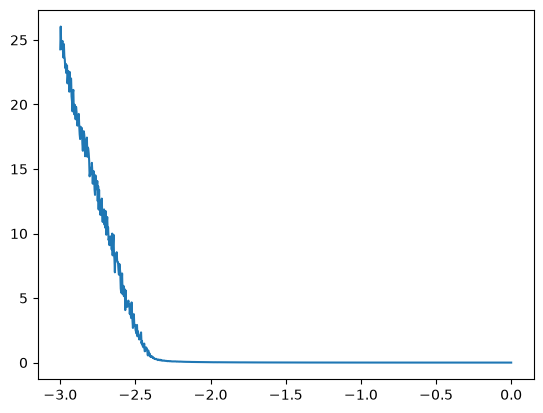

In [51]:
plt.plot(lri, lossi)